# Kode 1.1

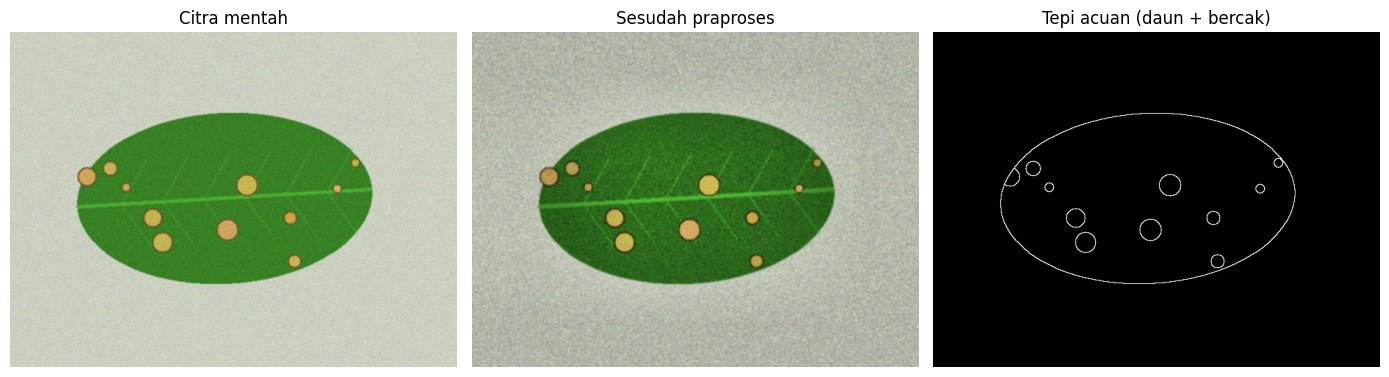

In [4]:
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])


# Tepi Canny

In [5]:
def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)


# Kode 3.1

         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.996                   171              11           0.583
1  teh_021.png          0.997                   222               3           0.074
2  teh_011.png          0.998                   197               0               -


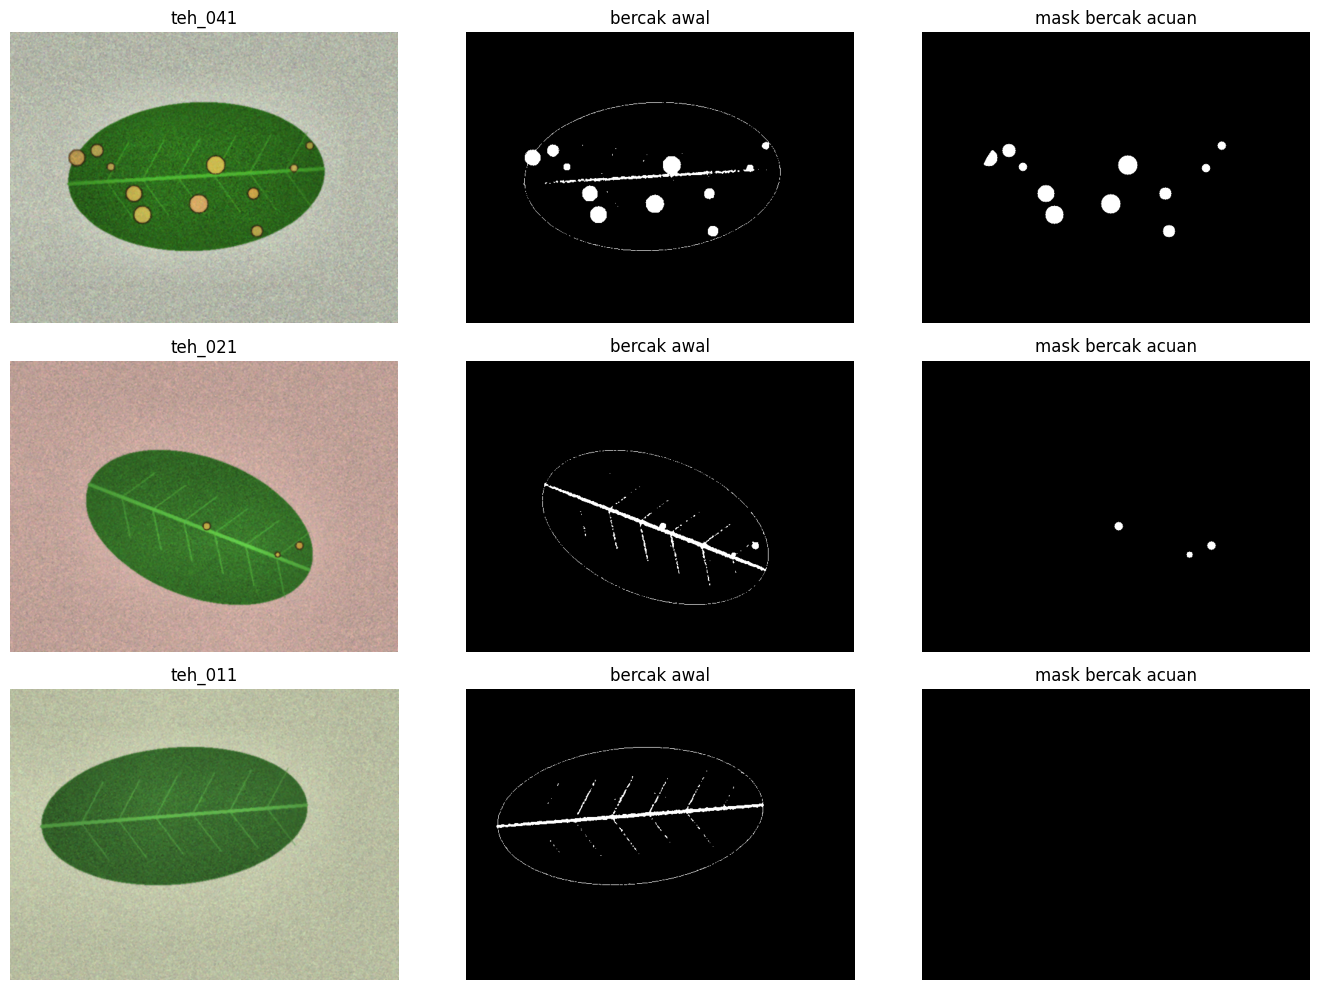

In [6]:
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:     # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)
    baris.append([nama, round(iou(m_daun, md), 3), jumlah_komponen(b0), jumlah_komponen(mb),
                  round(iou(b0, mb), 3) if mb.any() else "-"])
    panel += [pra_, b0, mb]; judul += [nama[:7], "bercak awal", "mask bercak acuan"]
print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal",
                                   "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))


# Kode 3.2

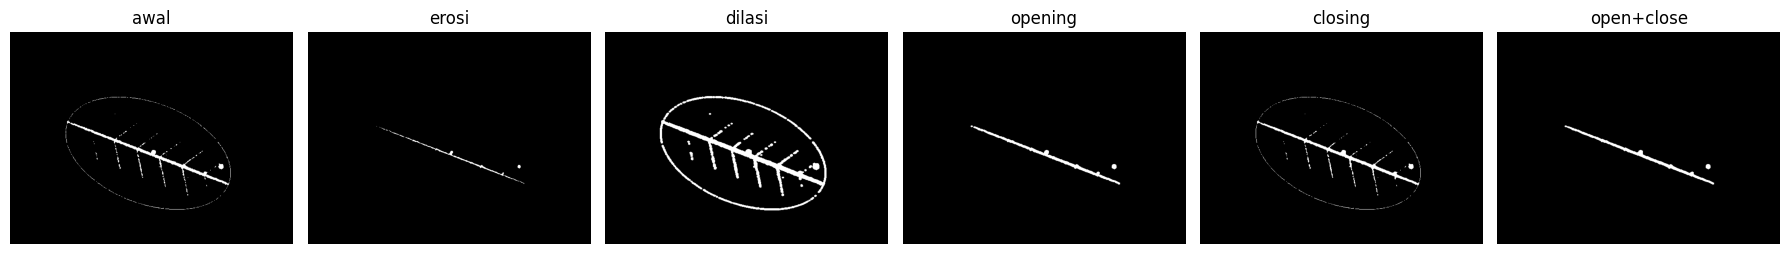

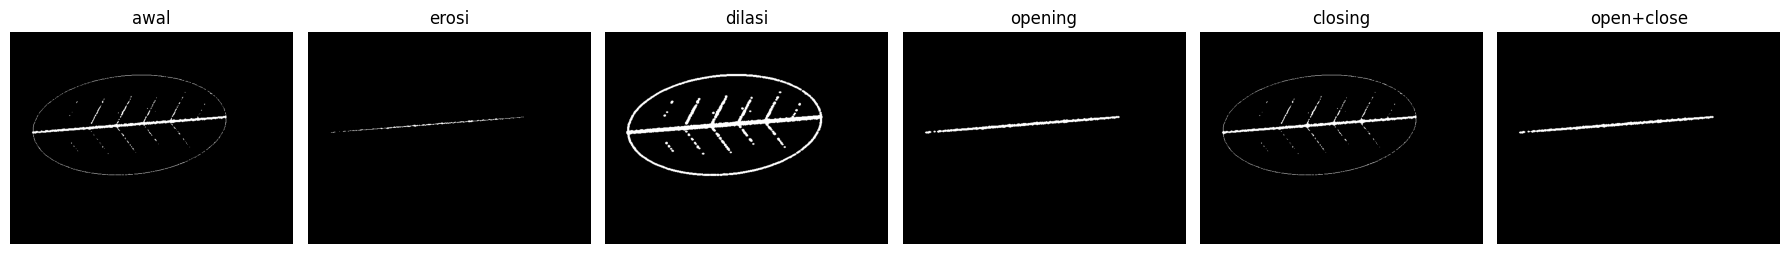

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       222    3792  0.074
1   teh_021.png       erosi        10     865  0.121
2   teh_021.png      dilasi        23   11356  0.033
3   teh_021.png     opening         3    2348  0.113
4   teh_021.png     closing       193    3975  0.074
5   teh_021.png  open+close         2    2387  0.115
6   teh_011.png        awal       197    3934      -
7   teh_011.png       erosi        16     712      -
8   teh_011.png      dilasi        30   12175      -
9   teh_011.png     opening         3    2417      -
10  teh_011.png     closing       184    4013      -
11  teh_011.png  open+close         2    2420      -


In [7]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
         baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                       round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3))
    plt.show()
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]))


# Kode 3.3

In [8]:
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m) - n_acuan),
                              iou(m, mb) if mb.any() else np.nan])
eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas", values=["galat_jumlah", "IoU"]).round(2))
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)


                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.60   0.15        15.05  22.10  67.15
          5       0.63   0.24         4.45   4.05   5.20
          7       0.68   0.34         2.10   2.25   2.70
  persegi 3       0.61   0.18         8.15   8.45  15.40
          5       0.66   0.30         2.75   2.80   3.95
          7       0.67   0.40         0.20   0.90   0.65
  silang  3       0.60   0.15        15.05  22.10  67.15
          5       0.64   0.23         7.35   6.85   9.40
          7       0.69   0.33         3.90   4.25   5.60
4 elips   3       0.65   0.24        12.50  16.60  53.70
          5       0.67   0.32         2.70   3.00   3.50
          7       0.68   0.41         0.70   1.45   1.20
  persegi 3       0.66   0.28         6.35   6.40  12.60
          5       0.68   0.35         1.70   2.15   1.75
          7       0.65   0.39  

# Kode 3.4

In [9]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))   # dilasi - erosi
    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])
print(pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"])
       .groupby("kondisi").mean().round(3))


                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.788     0.696
gelap                          0.982     0.745
kontras_rendah                 0.196     0.916
normal                         0.989     0.699
terang                         0.918     0.718


# Langkah 3.6

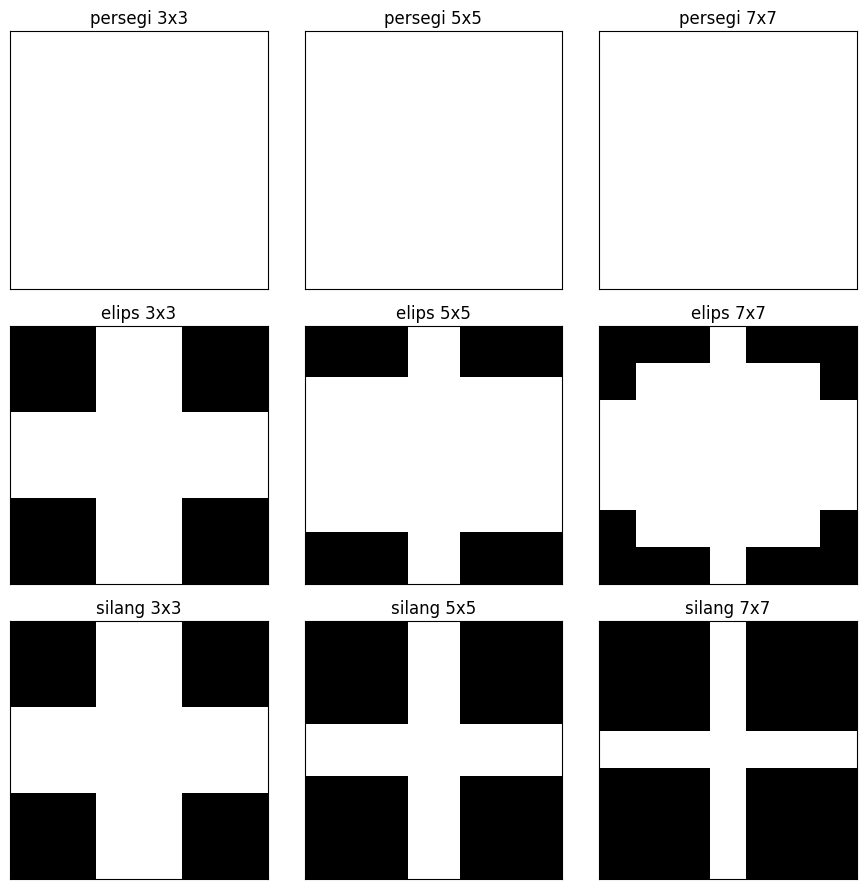

In [10]:
fig, ax = plt.subplots(3, 3, figsize=(9, 9))
for i, (nb, kb) in enumerate(bentuk.items()):
    for j, uk in enumerate([3, 5, 7]):
        se = SE(uk, kb)
        ax[i, j].imshow(se * 255, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax[i, j].set_title(f"{nb} {uk}x{uk}")
        ax[i, j].set_xticks([])
        ax[i, j].set_yticks([])
        ax[i, j].set_facecolor("black")
        for spine in ax[i, j].spines.values():
            spine.set_visible(True)
            spine.set_color("black")
plt.tight_layout()
plt.savefig("../hasil/p6_panel_se.png", dpi=150)
plt.show()


# Kode 4.1

In [11]:
MM_PER_PX = 0.4375                # dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                      cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1), round(kebulatan, 2),
                      round(rasio, 2), int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl


konektivitas 4: 14 komponen
konektivitas 8: 14 komponen
    label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0       1      116     22.20         38.4       0.99         1.04  493  186
1       2      305     58.38         63.1       0.96         1.11  143  195
2       3      539    103.17         86.7       0.90         1.06  109  206
3       4     1004    192.17        234.7       0.23         2.27  345  223
4       5      105     20.10         35.3       1.06         1.00  166  222
5       6      119     22.78         40.1       0.93         1.09  468  224
6       7       17      3.25         13.7       1.15         1.25  432  230
7       8      302     57.80        174.9       0.12        13.58  276  239
8       9       97     18.57         61.9       0.32         4.27  216  243
9      10      522     99.91         82.8       0.96         1.04  203  265
10     11      244     46.70         56.6       0.96         1.06  400  266
11     12      703    134.56    

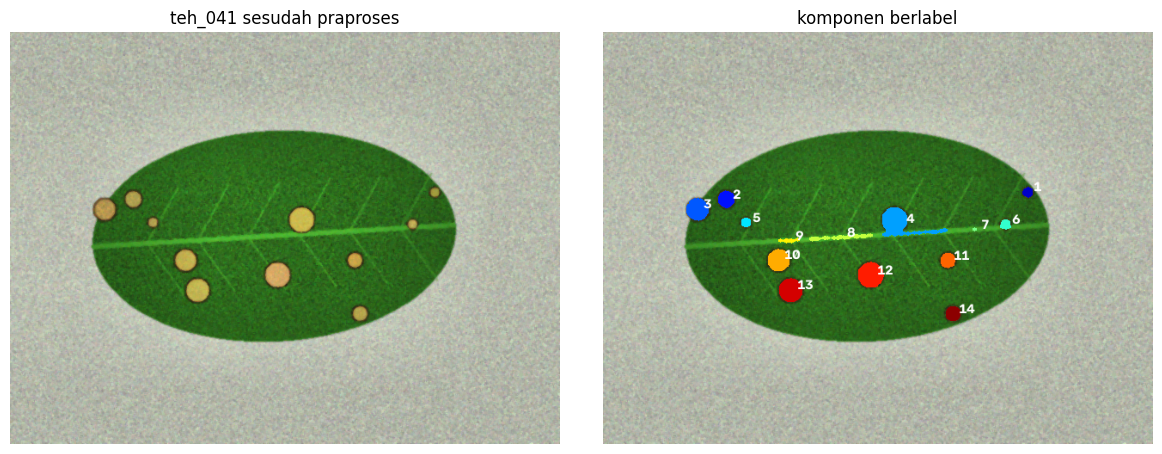

In [12]:
img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                          cv2.MORPH_CLOSE, SE(5))
for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")
tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)

warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))


#Kode 4.2

In [13]:
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >= bulat_min)
                    & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99), "luas + kebulatan + rasio": (20, 0.5, 1.8)}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])
uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
print(uji.pivot_table(index="aturan", columns="kelas", values="galat").round(2))
print("Daun sehat yang masih memiliki bercak palsu:")
print(uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0).groupby("aturan").palsu.sum())


kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           1.25    1.15   1.90
luas + kebulatan + rasio   0.60    0.70   0.85
luas >= 20                 2.10    1.80   2.95
tanpa saring               2.70    3.00   3.50
Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan            14
luas + kebulatan + rasio    11
luas >= 20                  15
tanpa saring                15
Name: palsu, dtype: int64


# Langkah 4.4

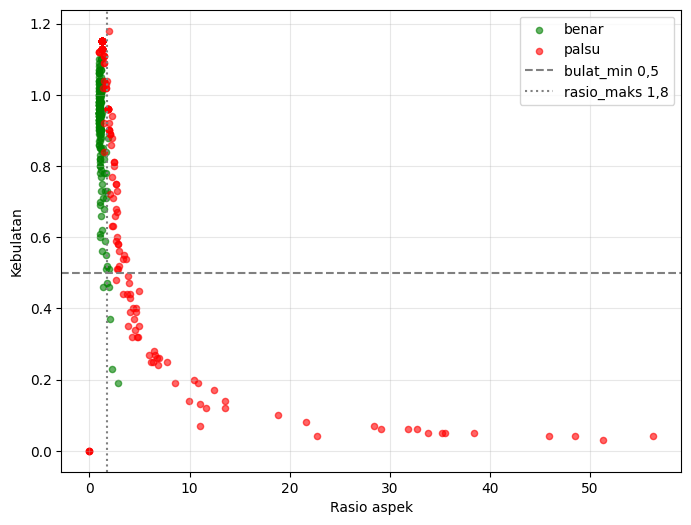

kelompok
benar    204
palsu    179
dtype: int64


In [14]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    tabel_k, lbl = ukur_komponen(bersih)
    for _, r in tabel_k.iterrows():
        piksel = (lbl == r.label)
        fraksi = (piksel & (mb > 0)).sum() / max(piksel.sum(), 1)
        baris.append([r.kebulatan, r.rasio_aspek, r.luas_px, "benar" if fraksi > 0.5 else "palsu"])
kom = pd.DataFrame(baris, columns=["kebulatan", "rasio_aspek", "luas_px", "kelompok"])

plt.figure(figsize=(8, 6))
for nama, warna in [("benar", "green"), ("palsu", "red")]:
    s = kom[kom.kelompok == nama]
    plt.scatter(s.rasio_aspek, s.kebulatan, c=warna, label=nama, alpha=0.6, s=20)
plt.axhline(0.5, color="gray", linestyle="--", label="bulat_min 0,5")
plt.axvline(1.8, color="gray", linestyle=":", label="rasio_maks 1,8")
plt.xlabel("Rasio aspek")
plt.ylabel("Kebulatan")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig("../hasil/p6_scatter_komponen.png", dpi=150)
plt.show()
print(kom.groupby("kelompok").size())


# Langkah 5.1

In [15]:
%%writefile ../src/bercak.py
"""bercak.py: analisis bercak SIMUTEH (dipakai ulang mulai P7)."""
import json
import cv2
import numpy as np
from utils_tepi import mask_daun_awal, bercak_awal

PARAM_BERCAK = {
    "kanal": 2,           # kanal terpilih (2 = R)
    "k": 4.0,             # ambang median + k x MAD
    "se_bentuk": "elips", # "elips", "persegi", "silang"
    "se_open": 5,         # ukuran SE opening (0 = tidak dipakai)
    "se_close": 5,        # ukuran SE closing (0 = tidak dipakai)
    "luas_min": 20,       # piksel
    "bulat_min": 0.5,
    "rasio_maks": 1.8,
    "batas_ringan": 0.1,  # persen bercak minimum kelas Ringan
    "batas_berat": 2.0,   # persen bercak minimum kelas Berat
    "mm_per_px": 0.4375,
}
_BENTUK = {"elips": cv2.MORPH_ELLIPSE, "persegi": cv2.MORPH_RECT, "silang": cv2.MORPH_CROSS}


def _se(p, uk):
    return cv2.getStructuringElement(_BENTUK[p["se_bentuk"]], (uk, uk))


def bersihkan(biner, p):
    """Opening membuang titik derau dan potongan tipis; closing menutup celah."""
    if p["se_open"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_OPEN, _se(p, p["se_open"]))
    if p["se_close"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_CLOSE, _se(p, p["se_close"]))
    return biner


def ukur_dan_saring(biner, p):
    """Mengembalikan mask bercak tersaring dan daftar ukuran setiap bercak."""
    n, lbl, st, cen = cv2.connectedComponentsWithStats((biner > 0).astype(np.uint8), connectivity=8)
    keluar, daftar = np.zeros_like(biner), []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                     cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        if A >= p["luas_min"] and kebulatan >= p["bulat_min"] and rasio <= p["rasio_maks"]:
            keluar[lbl == i] = 255
            daftar.append({"label": i, "luas_px": A, "luas_mm2": round(A * p["mm_per_px"] ** 2, 2),
                           "keliling_px": round(float(keliling), 1), "kebulatan": round(float(kebulatan), 2),
                           "rasio_aspek": round(float(rasio), 2),
                           "cx": int(cen[i][0]), "cy": int(cen[i][1])})
    return keluar, daftar


def analisis_daun(img_praproses, p=None):
    """Masukan: citra BGR hasil praproses. Keluaran: kamus hasil analisis."""
    p = {**PARAM_BERCAK, **(p or {})}
    m_daun = mask_daun_awal(img_praproses)
    biner = bercak_awal(img_praproses, m_daun, kanal=p["kanal"], k=p["k"])
    m_bercak, daftar = ukur_dan_saring(bersihkan(biner, p), p)
    luas_daun = int((m_daun > 0).sum())
    luas_bercak = int((m_bercak > 0).sum())
    persen = luas_bercak / luas_daun * 100 if luas_daun > 0 else 0.0
    if persen < p["batas_ringan"]:
        kelas = "Sehat"
    elif persen < p["batas_berat"]:
        kelas = "Ringan"
    else:
        kelas = "Berat"
    return {"mask_daun": m_daun, "mask_bercak": m_bercak, "jumlah_bercak": len(daftar),
             "persen_bercak": round(float(persen), 3), "kelas": kelas, "bercak": daftar}


def simpan_param(p, path="../hasil/param_bercak.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BERCAK, **p}, f, indent=2)


Overwriting ../src/bercak.py


In [16]:
from bercak import analisis_daun
h = analisis_daun(praproses(muat("teh_041.png")[0], PARAM))
print(h["jumlah_bercak"], h["persen_bercak"], h["kelas"])


10 4.304 Berat


# Kode 5.2

Galat absolut rerata persen bercak: 0.549
Korelasi persen prediksi vs acuan : 0.973
Akurasi kelas                                  : 0.867
prediksi       Berat  Ringan  Sehat
acuan                              
Bercak Berat      18       2      0
Bercak Ringan      0      16      4
Sehat              0       2     18
kondisi
bayangan          0.83
gelap             1.00
kontras_rendah    0.75
normal            0.92
terang            0.83
Name: benar, dtype: float64


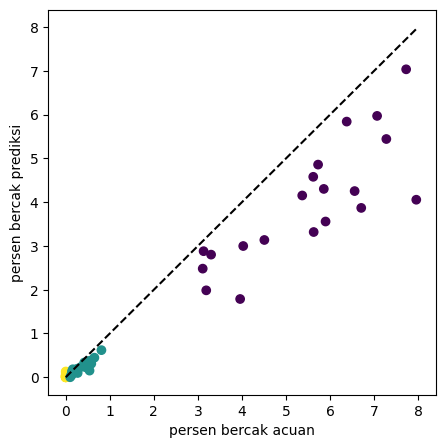

In [17]:
import importlib, bercak
importlib.reload(bercak)
PB = {}                                                           # ubah parameter sesuai temuan Anda
bercak.simpan_param(PB)

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"],
                  jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan", "persen_prediksi",
                                  "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)

peta = {"Berat": "Bercak Berat", "Ringan": "Bercak Ringan", "Sehat": "Sehat"}
print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas                                  :", (ev.kelas_prediksi.map(peta) == ev.kelas_acuan).mean().round(3))
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))
print(ev.assign(benar=ev.kelas_prediksi.map(peta) == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))

plt.figure(figsize=(5, 5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes)
plt.plot([0, 8], [0, 8], "k--"); plt.xlabel("persen bercak acuan"); plt.ylabel("persen bercak prediksi")
plt.show()


# Langkah 5.3

Jumlah salah kelas: 8


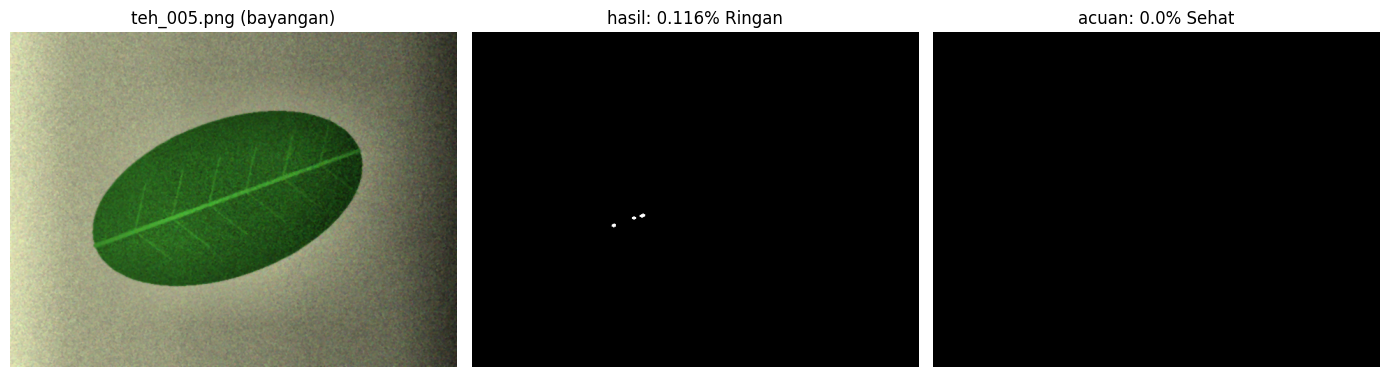

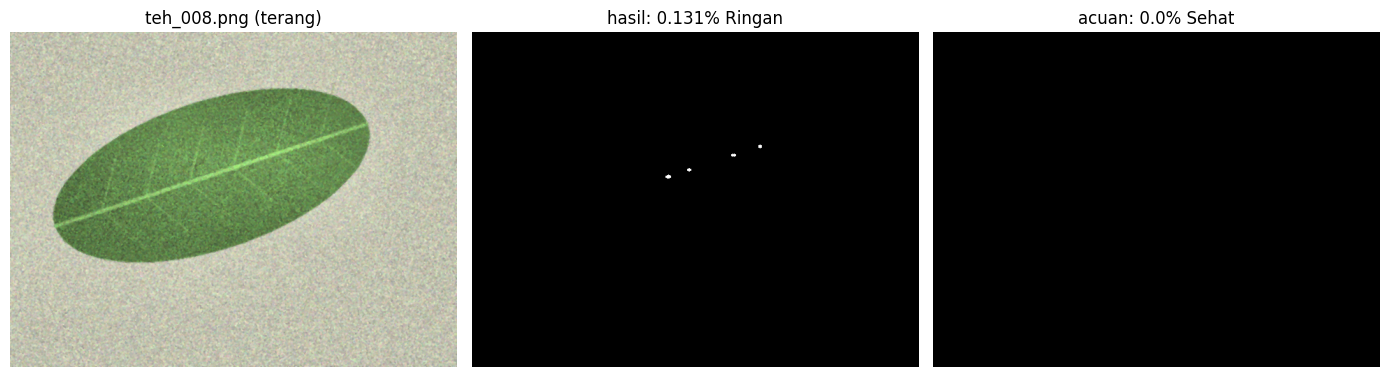

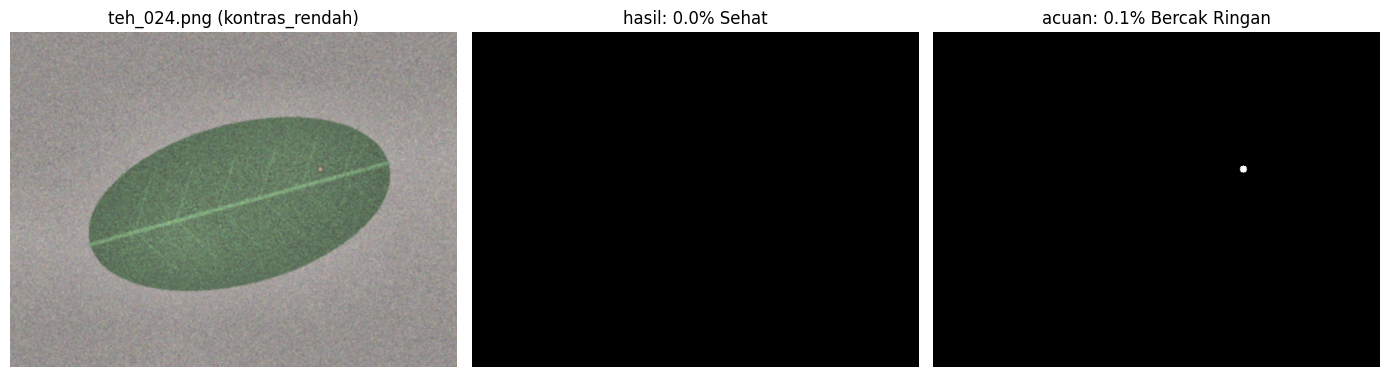

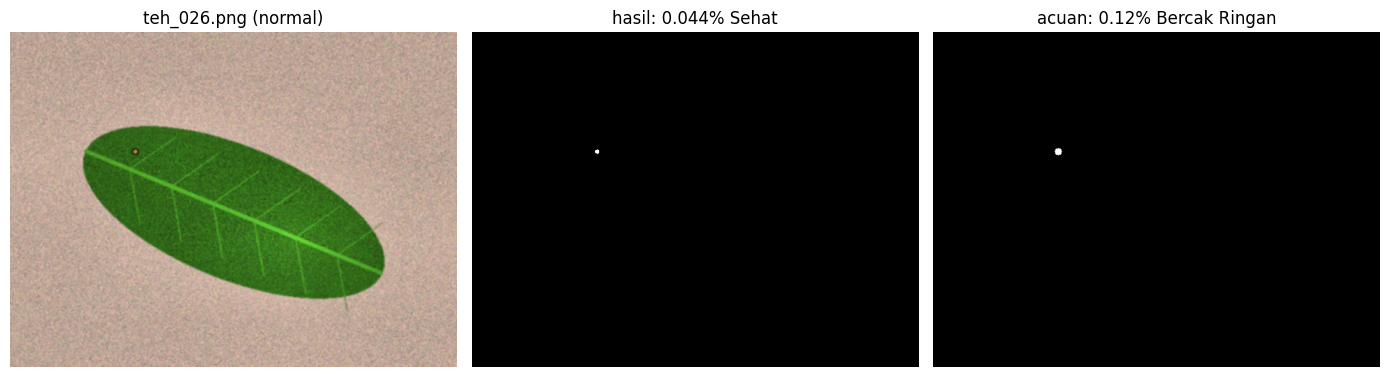

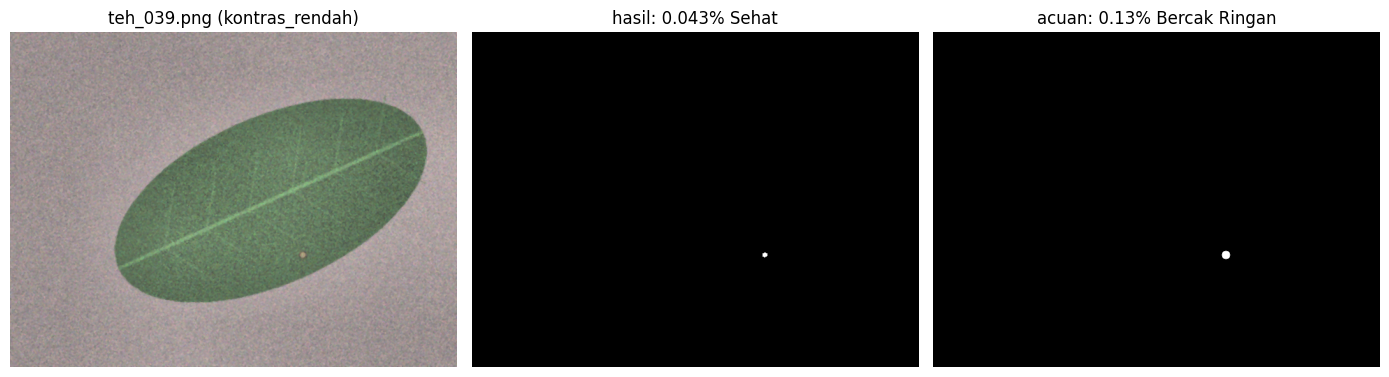

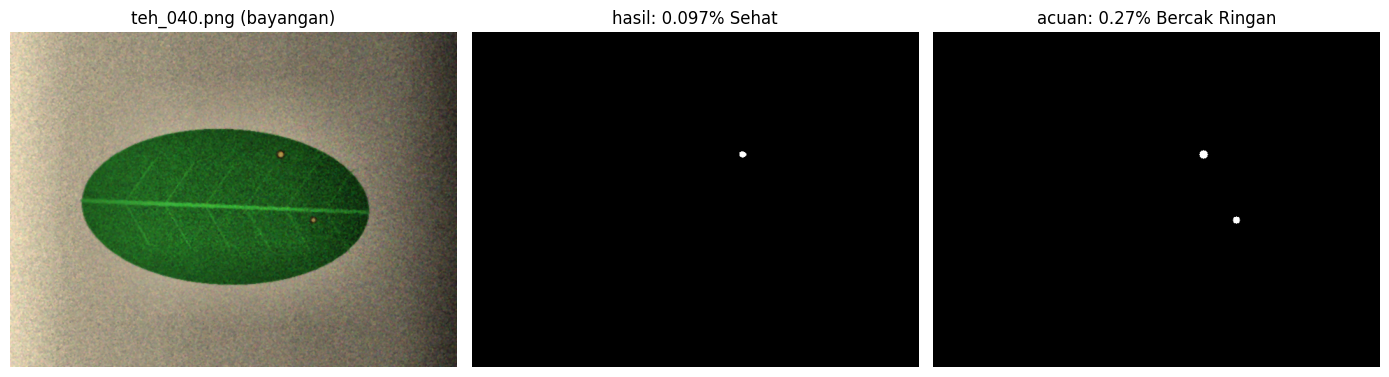

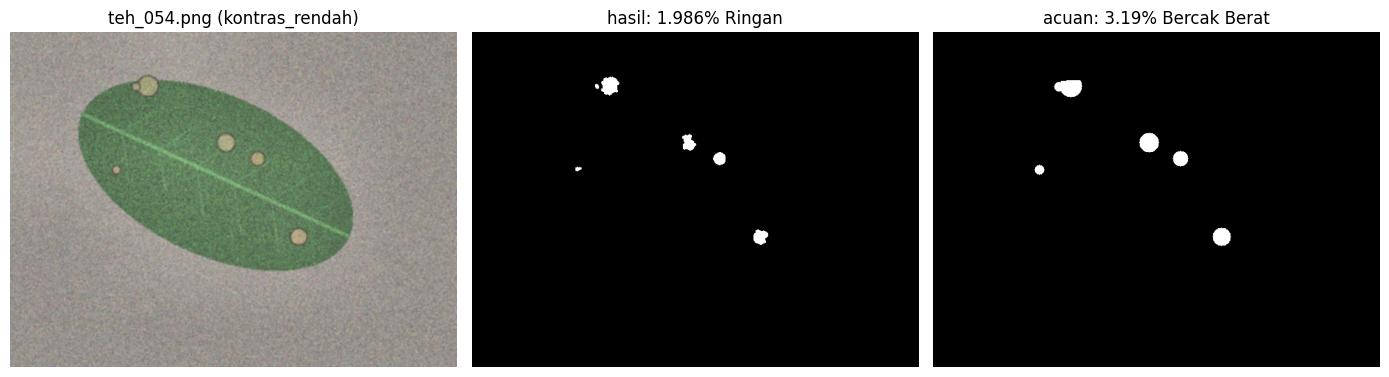

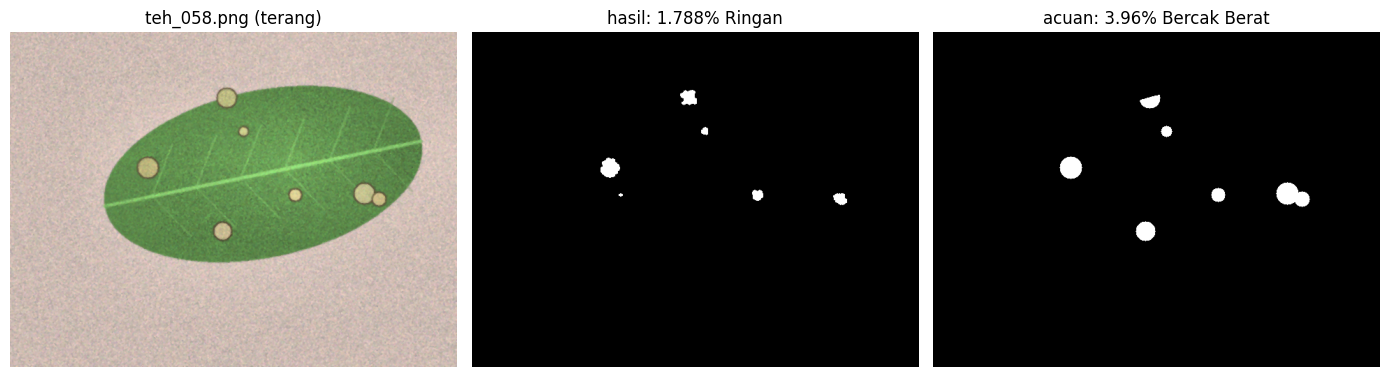

In [18]:
salah = ev[ev.kelas_prediksi.map(peta) != ev.kelas_acuan]
print("Jumlah salah kelas:", len(salah))
for _, d in salah.iterrows():
    img, md, mb = muat(d.nama)
    pra_ = praproses(img, PARAM)
    h = bercak.analisis_daun(pra_, PB)
    tampil([pra_, h["mask_bercak"], mb],
           [f"{d.nama} ({d.kondisi})", f"hasil: {h['persen_bercak']}% {h['kelas']}", f"acuan: {d.persen_acuan}% {d.kelas_acuan}"],
           ukuran=(14, 4.5))
    plt.show()
